# 병리 조직 이미지 분류 (PathMNIST) — PyTorch 실험

대장(colon) 병리 조직 패치 이미지를 **9가지 조직 종류**로 분류하는 딥러닝 모델을 직접 만들고 비교해 보는 프로젝트.

**이 노트북에서 하는 것**
1. 병리 영상 데이터 불러오기와 전처리 (패치 이미지, 데이터 증강)
2. 모델 2개 설계: 직접 만든 **CNN** vs 사전학습된 **ResNet18(레즈넷)**
3. 학습 → 검증 → 테스트 성능 평가 (Accuracy 정확도, AUC)
4. **오류 분석**: 혼동행렬(confusion matrix), 틀린 이미지 직접 보기
5. **재현성** 확보: 시드(seed) 고정, 설정·결과 저장

> ⚙️ 실행 전에: 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 선택 후 **런타임 → 모두 실행**

## 1. 환경 준비

In [1]:
!pip -q install medmnist

In [2]:
import os, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

import medmnist
from medmnist import INFO
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__, '| medmnist', medmnist.__version__)
if device == 'cpu':
    print('⚠️ GPU가 꺼져 있어요. 런타임 → 런타임 유형 변경 → T4 GPU 로 바꾸고 다시 실행하세요.')

device: cuda | torch 2.14.1+cu130 | medmnist 3.0.2


## 2. 실험 설정 + 재현성(시드 고정)

같은 코드를 다시 돌려도 **같은 결과**가 나오도록 난수 시드를 고정한다.
연구에서는 결과를 다른 사람이 다시 만들어 낼 수 있어야 하기 때문(재현성).

In [3]:
CFG = dict(
    data_flag='pathmnist',  # 대장 병리 조직 데이터셋
    img_size=28,            # 28 / 64 / 128 / 224 가능 (클수록 정확하지만 느림)
    batch_size=128,
    epochs=10,              # 에폭(epoch): 전체 데이터를 몇 번 반복 학습할지
    lr=1e-3,                # 학습률(learning rate)
    seed=42,
)
OUT = 'outputs'
os.makedirs(OUT, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CFG['seed'])
CFG

{'data_flag': 'pathmnist',
 'img_size': 28,
 'batch_size': 128,
 'epochs': 10,
 'lr': 0.001,
 'seed': 42}

## 3. 데이터 불러오기

PathMNIST = 대장암 조직 슬라이드(WSI)에서 잘라낸 **패치 이미지** 약 10만 장. 학습/검증/테스트로 이미 나뉘어 있다.

In [4]:
info = INFO[CFG['data_flag']]
DataClass = getattr(medmnist, info['python_class'])
n_classes = len(info['label'])
class_names = [info['label'][str(i)] for i in range(n_classes)]
size_kw = {} if CFG['img_size'] == 28 else {'size': CFG['img_size']}

print(info['description'])
print()
for i, name in enumerate(class_names):
    print(i, name)

The PathMNIST is based on a prior study for predicting survival from colorectal cancer histology slides, providing a dataset (NCT-CRC-HE-100K) of 100,000 non-overlapping image patches from hematoxylin & eosin stained histological images, and a test dataset (CRC-VAL-HE-7K) of 7,180 image patches from a different clinical center. The dataset is comprised of 9 types of tissues, resulting in a multi-class classification task. We resize the source images of 3×224×224 into 3×28×28, and split NCT-CRC-HE-100K into training and validation set with a ratio of 9:1. The CRC-VAL-HE-7K is treated as the test set.

0 adipose
1 background
2 debris
3 lymphocytes
4 mucus
5 smooth muscle
6 normal colon mucosa
7 cancer-associated stroma
8 colorectal adenocarcinoma epithelium


### 전처리와 데이터 증강(augmentation)

병리 조직 사진은 **뒤집거나 90도 돌려도 같은 조직**이다.
그래서 학습할 때 이미지를 무작위로 뒤집고 돌려서 데이터를 늘리고, 모델이 방향에 휘둘리지 않게 한다.
검증·테스트 데이터에는 증강을 하지 않는다 (공정한 평가를 위해).

In [5]:
class RandomRot90:
    """0/90/180/270도 중 하나로 무작위 회전 (모서리에 검은 빈칸이 생기지 않음)"""
    def __call__(self, x):
        return torch.rot90(x, random.randint(0, 3), dims=[1, 2])

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet 정규화 값

train_tf = T.Compose([
    T.ToTensor(),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    RandomRot90(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

train_ds = DataClass(split='train', transform=train_tf, download=True, **size_kw)
val_ds   = DataClass(split='val',   transform=eval_tf,  download=True, **size_kw)
test_ds  = DataClass(split='test',  transform=eval_tf,  download=True, **size_kw)
test_raw = DataClass(split='test', download=True, **size_kw)  # 오류 분석 때 원본 이미지 보기용

print('train', len(train_ds), '| val', len(val_ds), '| test', len(test_ds))

100%|██████████| 206M/206M [01:14<00:00, 2.76MB/s]


train 89996 | val 10004 | test 7180


### 클래스별 데이터 개수 확인 (불균형이 있는지)

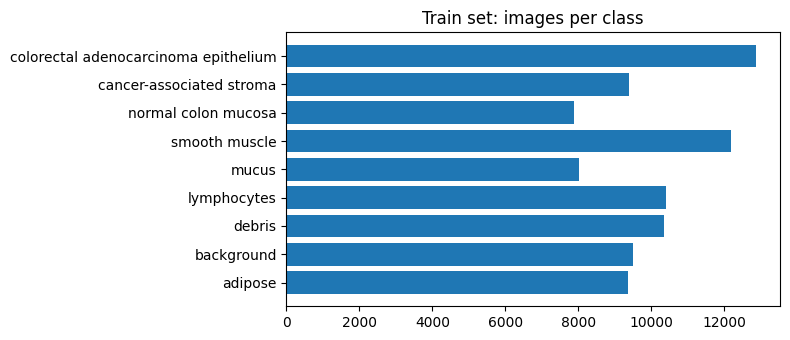

In [6]:
counts = np.bincount(train_ds.labels.squeeze(), minlength=n_classes)
plt.figure(figsize=(8, 3.5))
plt.barh(class_names, counts)
plt.title('Train set: images per class')
plt.tight_layout(); plt.savefig(f'{OUT}/class_counts.png', dpi=150); plt.show()

### 샘플 이미지 보기

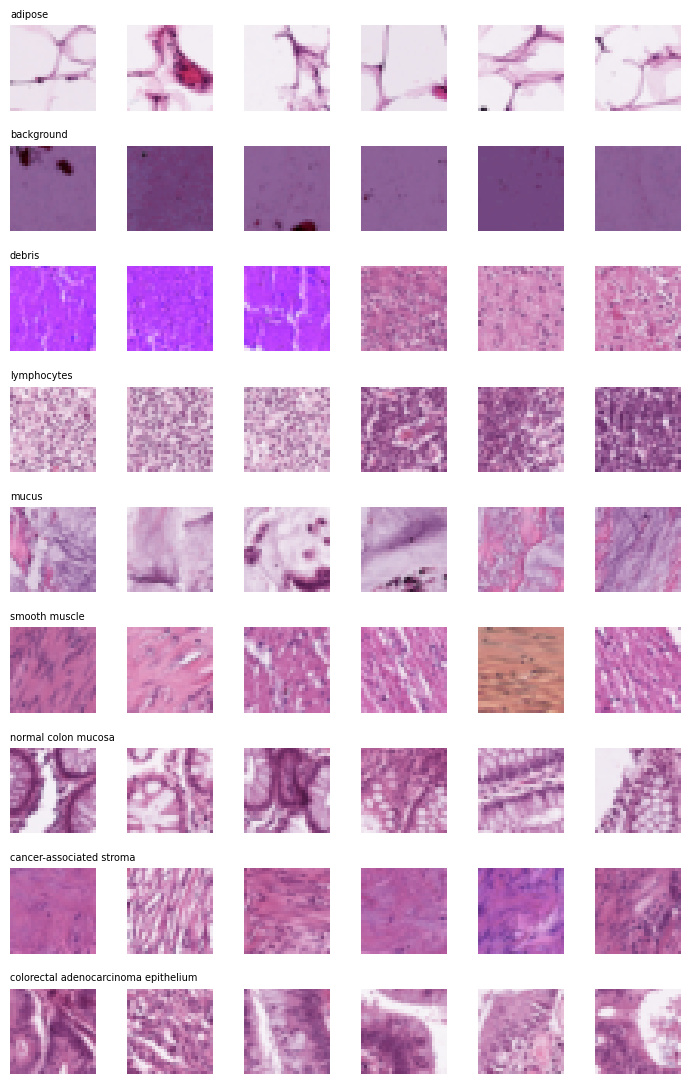

In [7]:
fig, axes = plt.subplots(n_classes, 6, figsize=(7, 11))
for c in range(n_classes):
    idx = np.where(test_raw.labels.squeeze() == c)[0][:6]
    for j, i in enumerate(idx):
        axes[c, j].imshow(test_raw.imgs[i]); axes[c, j].axis('off')
    axes[c, 0].set_title(class_names[c], fontsize=7, loc='left')
plt.tight_layout(); plt.savefig(f'{OUT}/samples.png', dpi=150); plt.show()

## 4. 모델 설계

| 모델 | 설명 |
|---|---|
| **SimpleCNN** | 직접 쌓은 작은 합성곱 신경망. 기준선(baseline) |
| **ResNet18** | ImageNet으로 미리 학습된 모델을 가져와 병리 이미지에 맞게 다시 학습 (전이학습, transfer learning) |

28×28처럼 작은 이미지는 ResNet 첫 부분에서 크기를 너무 많이 줄이면 정보가 사라진다.
그래서 첫 합성곱을 3×3으로 바꾸고 maxpool(맥스풀)을 뺐다.

In [8]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def make_resnet18(n_classes):
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    if CFG['img_size'] <= 64:
        m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
        m.maxpool = nn.Identity()
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m

MODELS = {
    'SimpleCNN': lambda: SimpleCNN(n_classes),
    'ResNet18':  lambda: make_resnet18(n_classes),
}
for name, build in MODELS.items():
    n_params = sum(p.numel() for p in build().parameters())
    print(f'{name}: {n_params/1e6:.2f}M parameters')

SimpleCNN: 0.29M parameters
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 121MB/s]


ResNet18: 11.17M parameters


## 5. 학습 / 평가 함수

- 손실함수: CrossEntropy (다중 분류용)
- 최적화: AdamW + Cosine 학습률 스케줄
- 매 에폭마다 **검증(val) AUC가 가장 좋은 모델**을 저장 → 과적합(overfitting)된 마지막 모델 대신 가장 좋았던 시점을 사용

In [9]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, probs_list, labels_list = 0.0, [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.view(-1).long().to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            probs_list.append(out.softmax(1).detach().cpu())
            labels_list.append(y.cpu())
    probs = torch.cat(probs_list).numpy().astype('float64')
    probs /= probs.sum(1, keepdims=True)
    labels = torch.cat(labels_list).numpy()
    acc = (probs.argmax(1) == labels).mean()
    auc = roc_auc_score(labels, probs, multi_class='ovr')
    return total_loss / len(labels), acc, auc, probs, labels


def train_model(name, build_fn):
    set_seed(CFG['seed'])
    model = build_fn().to(device)
    g = torch.Generator().manual_seed(CFG['seed'])
    train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True, num_workers=2, generator=g)
    val_loader = DataLoader(val_ds, batch_size=256, num_workers=2)

    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG['epochs'])

    history, best_auc = [], -1
    for epoch in range(1, CFG['epochs'] + 1):
        t0 = time.time()
        tr_loss, tr_acc, _, _, _ = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc, va_auc, _, _ = run_epoch(model, val_loader)
        scheduler.step()
        history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                            val_loss=va_loss, val_acc=va_acc, val_auc=va_auc))
        mark = ''
        if va_auc > best_auc:
            best_auc = va_auc
            torch.save(model.state_dict(), f'{OUT}/{name}_best.pt')
            mark = '  ← best 저장'
        print(f'[{name}] epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} auc {va_auc:.4f} | {time.time()-t0:.0f}s{mark}')

    model.load_state_dict(torch.load(f'{OUT}/{name}_best.pt'))
    return model, pd.DataFrame(history)

## 6. 실험 실행 (두 모델 학습)
T4 GPU 기준 몇 분 정도 걸린다.

In [10]:
results, histories, trained = {}, {}, {}
for name, build in MODELS.items():
    model, hist = train_model(name, build)
    trained[name], histories[name] = model, hist

[SimpleCNN] epoch  1 | train loss 0.496 acc 0.823 | val loss 0.331 acc 0.886 auc 0.9919 | 33s  ← best 저장
[SimpleCNN] epoch  2 | train loss 0.256 acc 0.912 | val loss 1.048 acc 0.751 auc 0.9755 | 29s
[SimpleCNN] epoch  3 | train loss 0.193 acc 0.933 | val loss 0.618 acc 0.800 auc 0.9878 | 28s
[SimpleCNN] epoch  4 | train loss 0.155 acc 0.948 | val loss 0.479 acc 0.843 auc 0.9933 | 28s  ← best 저장
[SimpleCNN] epoch  5 | train loss 0.132 acc 0.955 | val loss 0.167 acc 0.945 auc 0.9976 | 28s  ← best 저장
[SimpleCNN] epoch  6 | train loss 0.107 acc 0.964 | val loss 0.137 acc 0.952 auc 0.9987 | 30s  ← best 저장
[SimpleCNN] epoch  7 | train loss 0.088 acc 0.971 | val loss 0.131 acc 0.956 auc 0.9988 | 29s  ← best 저장
[SimpleCNN] epoch  8 | train loss 0.076 acc 0.974 | val loss 0.066 acc 0.980 auc 0.9995 | 30s  ← best 저장
[SimpleCNN] epoch  9 | train loss 0.064 acc 0.978 | val loss 0.054 acc 0.983 auc 0.9996 | 29s  ← best 저장
[SimpleCNN] epoch 10 | train loss 0.059 acc 0.980 | val loss 0.051 acc 0.984 

### 학습 곡선 — 과적합 여부 확인
train loss는 계속 내려가는데 val loss가 올라가기 시작하면 과적합 신호.

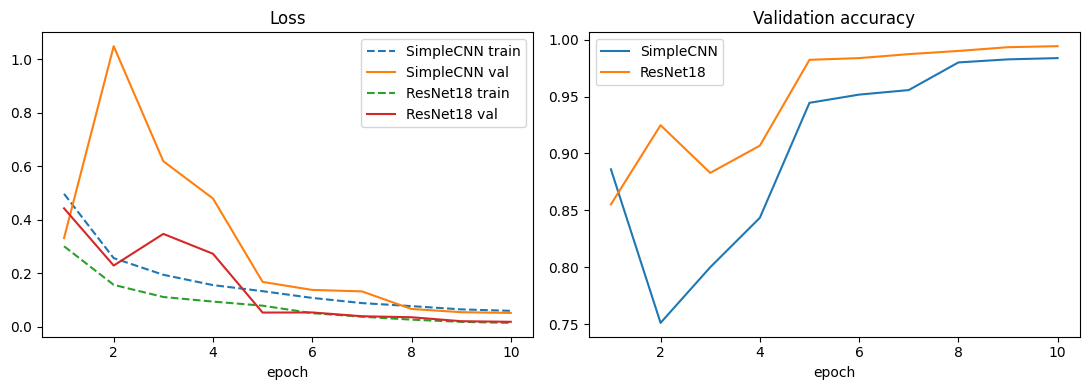

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, h in histories.items():
    axes[0].plot(h.epoch, h.train_loss, '--', label=f'{name} train')
    axes[0].plot(h.epoch, h.val_loss, label=f'{name} val')
    axes[1].plot(h.epoch, h.val_acc, label=name)
axes[0].set_title('Loss'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].set_title('Validation accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/learning_curves.png', dpi=150); plt.show()

## 7. 테스트셋 최종 평가
학습·모델 선택에 한 번도 쓰지 않은 테스트 데이터로 마지막에 딱 한 번 평가한다.

In [12]:
test_loader = DataLoader(test_ds, batch_size=256, num_workers=2)
test_out = {}
for name, model in trained.items():
    _, acc, auc, probs, labels = run_epoch(model, test_loader)
    test_out[name] = (probs, labels)
    results[name] = dict(test_acc=round(float(acc), 4), test_auc=round(float(auc), 4),
                         best_val_auc=round(float(histories[name].val_auc.max()), 4))

summary = pd.DataFrame(results).T
summary

,test_acc,test_auc,best_val_auc
SimpleCNN,0.8947,0.9883,0.9997
ResNet18,0.9050,0.9915,1.0000


## 8. 오류 분석

가장 성능이 좋은 모델로 **어떤 조직끼리 헷갈리는지** 확인한다.

best model: ResNet18


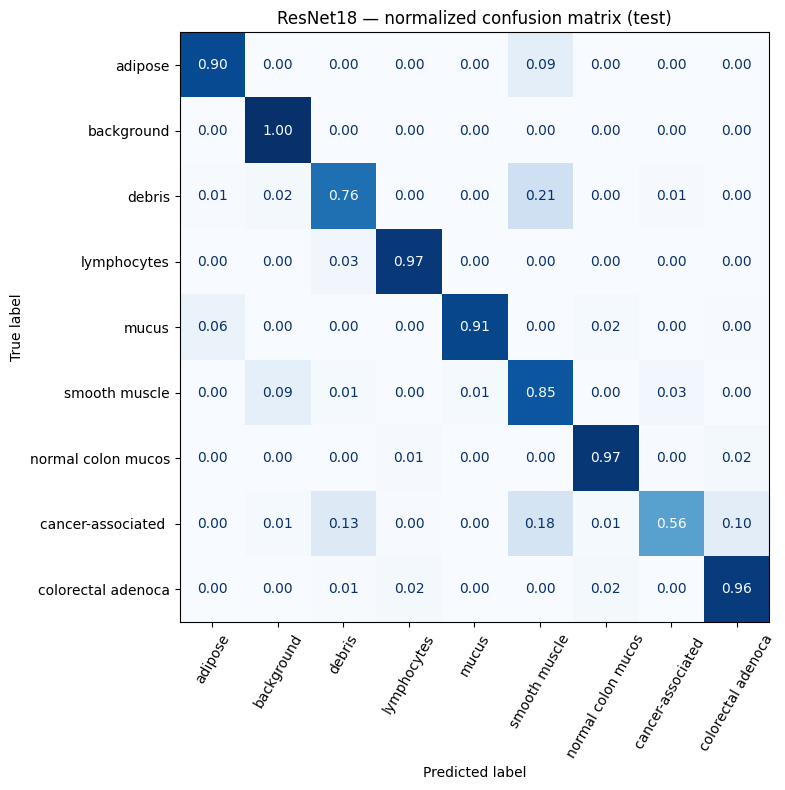

                                      precision    recall  f1-score   support

                             adipose      0.947     0.898     0.922      1338
                          background      0.923     1.000     0.960       847
                              debris      0.729     0.755     0.742       339
                         lymphocytes      0.955     0.968     0.962       634
                               mucus      0.988     0.912     0.949      1035
                       smooth muscle      0.650     0.855     0.738       592
                 normal colon mucosa      0.942     0.969     0.955       741
            cancer-associated stroma      0.903     0.556     0.688       421
colorectal adenocarcinoma epithelium      0.946     0.955     0.951      1233

                            accuracy                          0.905      7180
                           macro avg      0.887     0.874     0.874      7180
                        weighted avg      0.913     0.905     

In [13]:
best_name = summary.test_auc.idxmax()
probs, labels = test_out[best_name]
preds = probs.argmax(1)
print('best model:', best_name)

cm = confusion_matrix(labels, preds, normalize='true')
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=[n[:18] for n in class_names]).plot(
    ax=ax, cmap='Blues', values_format='.2f', xticks_rotation=60, colorbar=False)
ax.set_title(f'{best_name} — normalized confusion matrix (test)')
plt.tight_layout(); plt.savefig(f'{OUT}/confusion_matrix.png', dpi=150); plt.show()

print(classification_report(labels, preds, target_names=class_names, digits=3))

### 가장 많이 헷갈린 조합 Top 5

In [14]:
cm_counts = confusion_matrix(labels, preds)
np.fill_diagonal(cm_counts, 0)
pairs = sorted(((cm_counts[i, j], i, j) for i in range(n_classes) for j in range(n_classes) if cm_counts[i, j] > 0), reverse=True)[:5]
for cnt, i, j in pairs:
    print(f'정답 [{class_names[i]}] → 예측 [{class_names[j]}] : {cnt}장')

정답 [adipose] → 예측 [smooth muscle] : 126장
정답 [cancer-associated stroma] → 예측 [smooth muscle] : 75장
정답 [debris] → 예측 [smooth muscle] : 71장
정답 [mucus] → 예측 [adipose] : 65장
정답 [smooth muscle] → 예측 [background] : 55장


### 틀린 이미지 직접 보기
모델이 **자신 있게 틀린** 이미지부터 본다. 사람 눈에도 애매한지, 라벨이 이상한지 확인.

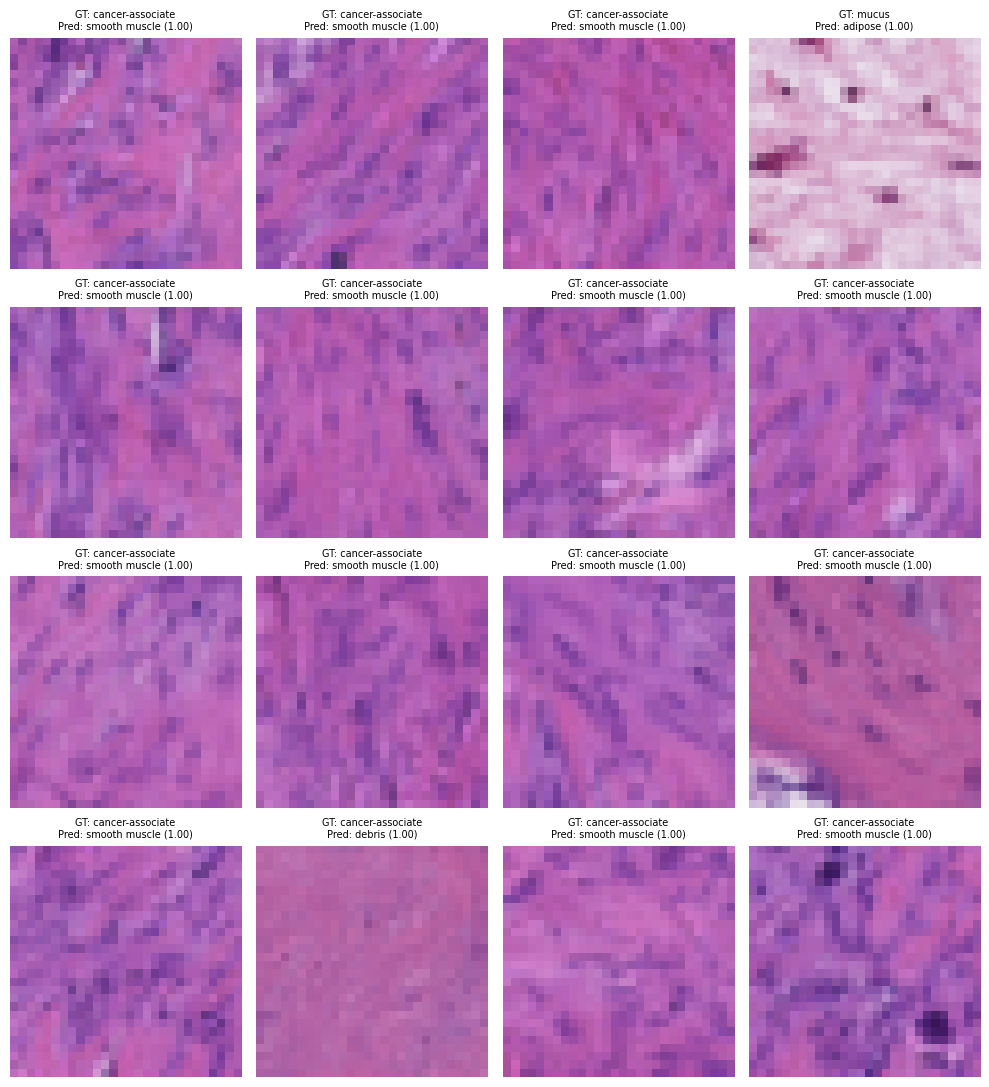

In [15]:
wrong = np.where(preds != labels)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:16]
fig, axes = plt.subplots(4, 4, figsize=(10, 11))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(test_raw.imgs[i]); ax.axis('off')
    ax.set_title(f'GT: {class_names[labels[i]][:16]}\nPred: {class_names[preds[i]][:16]} ({probs[i].max():.2f})', fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT}/misclassified.png', dpi=150); plt.show()

## 9. 설정과 결과 저장 (재현성)

In [16]:
record = dict(config=CFG, results=results, best_model=best_name,
              versions=dict(torch=torch.__version__, torchvision=torchvision.__version__, medmnist=medmnist.__version__),
              gpu=torch.cuda.get_device_name(0) if device == 'cuda' else 'cpu')
with open(f'{OUT}/results.json', 'w') as f:
    json.dump(record, f, indent=2, ensure_ascii=False)
for name, h in histories.items():
    h.to_csv(f'{OUT}/{name}_history.csv', index=False)
print(json.dumps(record, indent=2, ensure_ascii=False))

{
  "config": {
    "data_flag": "pathmnist",
    "img_size": 28,
    "batch_size": 128,
    "epochs": 10,
    "lr": 0.001,
    "seed": 42
  },
  "results": {
    "SimpleCNN": {
      "test_acc": 0.8947,
      "test_auc": 0.9883,
      "best_val_auc": 0.9997
    },
    "ResNet18": {
      "test_acc": 0.905,
      "test_auc": 0.9915,
      "best_val_auc": 1.0
    }
  },
  "best_model": "ResNet18",
  "versions": {
    "torch": "2.14.1+cu130",
    "torchvision": "0.29.1+cu130",
    "medmnist": "3.0.2"
  },
  "gpu": "Tesla T4"
}


### 결과 이미지·파일 내려받기 (GitHub에 올릴 용도, 모델 가중치 .pt 제외)

In [17]:
!cd {OUT} && zip -q -r ../results.zip . -x '*.pt'
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>